# TRABAJO 2. INFERENCIA ESTADÍSTICA.


In [1]:
# Importar librerías
import pandas as pd
import numpy as np
from scipy import stats
from scipy import optimize as opt  # para estimación por máxima verosimilitud
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.dpi'] = 75

from statsmodels.distributions.empirical_distribution import ECDF

import statsmodels.api as sm
from statsmodels.nonparametric.kde import KDEUnivariate

from statsmodels.nonparametric.kernel_density import KDEMultivariate
import matplotlib.tri as tri

In [2]:
import os
os.getcwd()

'/home/202500980@alu.comillas.edu/PRyES/Trabajos/TRABAJO_2'

In [3]:
nom_fi_datos_temp = 'G01A_2m_temperature.csv'
nom_fi_datos_irrad = 'G01A_surface_solar_radiation_downwards.csv'
nom_fi_datos_precip = 'G01A_total_precipitation.csv'

In [4]:
ruta_csv = os.path.join(f'{nom_fi_datos_temp}')
df_orig_temp = pd.read_csv(ruta_csv)

# parseamos la fecha (cadena) para que sea un datetime con formato yyyy/mm/dd 
df_orig_temp['FECHA'] = pd.to_datetime(df_orig_temp['FECHA'], format='%Y-%m-%d')

s = df_orig_temp.loc[:,'FECHA']
df_orig_temp['FECHA'] =  s.dt.date

print('Tamaño de df_orig_temp con los datos cargados:', df_orig_temp.shape)
print('Dataframe con todos los datos leidos (filas: días, columnas: variables):')
print(df_orig_temp)

Tamaño de df_orig_temp con los datos cargados: (4383, 15)
Dataframe con todos los datos leidos (filas: días, columnas: variables):
           FECHA  TEMP_CELDA01  TEMP_CELDA02  TEMP_CELDA03  TEMP_CELDA04  \
0     2014-01-01     10.507935     10.184529      9.885254     10.478923   
1     2014-01-02     12.103457     11.748009     11.428368     12.045392   
2     2014-01-03     13.271104     12.917161     12.594407     13.272590   
3     2014-01-04      9.909261      9.564168      9.260661     10.009114   
4     2014-01-05      8.723439      8.405385      8.029063      8.819285   
...          ...           ...           ...           ...           ...   
4378  2025-12-27      6.387714      6.120380      5.803303      6.213235   
4379  2025-12-28      8.558502      8.185231      7.769379      8.415436   
4380  2025-12-29      6.722017      6.538057      6.310599      6.873669   
4381  2025-12-30      7.366825      7.156376      6.944665      7.394962   
4382  2025-12-31      7.053768   

In [5]:
ruta_csv = os.path.join( f'{nom_fi_datos_irrad}')
df_orig_irrad = pd.read_csv(ruta_csv)

# parseamos la fecha (cadena) para que sea un datetime con formato yyyy/mm/dd 
df_orig_irrad['FECHA'] = pd.to_datetime(df_orig_irrad['FECHA'], format='%Y-%m-%d')

s = df_orig_irrad.loc[:,'FECHA']
df_orig_irrad['FECHA'] =  s.dt.date

print('Tamaño de df_orig_irrad con los datos cargados:', df_orig_irrad.shape)
print('Dataframe con todos los datos leidos (filas: días, columnas: variables):')
print(df_orig_irrad)

Tamaño de df_orig_irrad con los datos cargados: (4383, 15)
Dataframe con todos los datos leidos (filas: días, columnas: variables):
           FECHA  IRRAD_CELDA01  IRRAD_CELDA02  IRRAD_CELDA03  IRRAD_CELDA04  \
0     2014-01-01      216153.55     221514.200     226185.420     216941.500   
1     2014-01-02       46182.44      43555.484      41082.902      54423.234   
2     2014-01-03      151202.60     156498.840     161921.550     169761.100   
3     2014-01-04      131521.06     130642.310     130140.600     150176.730   
4     2014-01-05      291939.72     296379.380     301071.620     301388.280   
...          ...            ...            ...            ...            ...   
4378  2025-12-27      219719.12     229198.750     238696.170     198351.880   
4379  2025-12-28      302196.90     300463.500     298154.500     302508.840   
4380  2025-12-29      349713.75     348253.780     345809.720     351148.750   
4381  2025-12-30      314719.75     315519.470     316274.620     31

In [6]:
ruta_csv = os.path.join(f'{nom_fi_datos_precip}')
df_orig_precip = pd.read_csv(ruta_csv)

# parseamos la fecha (cadena) para que sea un datetime con formato yyyy/mm/dd 
df_orig_precip['FECHA'] = pd.to_datetime(df_orig_precip['FECHA'], format='%Y-%m-%d')

s = df_orig_precip.loc[:,'FECHA']
df_orig_precip['FECHA'] =  s.dt.date

print('Tamaño de df_orig_precip con los datos cargados:', df_orig_precip.shape)
print('Dataframe con todos los datos leidos (filas: días, columnas: variables):')
print(df_orig_precip)

Tamaño de df_orig_precip con los datos cargados: (4383, 15)
Dataframe con todos los datos leidos (filas: días, columnas: variables):
           FECHA  PRECIP_CELDA01  PRECIP_CELDA02  PRECIP_CELDA03  \
0     2014-01-01    1.726640e-05    2.184587e-05    2.634153e-05   
1     2014-01-02    1.975207e-04    1.818365e-04    1.648032e-04   
2     2014-01-03    1.714909e-04    2.023070e-04    2.303989e-04   
3     2014-01-04    3.041076e-04    3.009254e-04    2.952680e-04   
4     2014-01-05    4.802520e-07    3.720634e-07    2.610808e-07   
...          ...             ...             ...             ...   
4378  2025-12-27    2.070589e-04    2.158616e-04    2.297312e-04   
4379  2025-12-28    3.717894e-05    5.393328e-05    7.344698e-05   
4380  2025-12-29    1.091532e-05    1.293256e-05    1.453979e-05   
4381  2025-12-30    2.449622e-05    2.759179e-05    3.011753e-05   
4382  2025-12-31    8.997887e-08    6.990027e-08    5.610418e-08   

      PRECIP_CELDA04  PRECIP_CELDA05  PRECIP_CELDA

## 1. Contrastes de hipótesis para la media de la temperatura de la celda 01 en los meses de verano.

In [7]:
mes_ini = 6
mes_fin = 8

variables = ['TEMP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_temp.MES >= mes_ini) & (df_orig_temp.MES <= mes_fin)
df = df_orig_temp.loc[ind_filas, columnas]
print(df)

x = df.TEMP_CELDA01
n = len(x)

      DIASEM  MES  ANNO  TEMP_CELDA01
151        6    6  2014     20.242218
152        0    6  2014     21.714142
153        1    6  2014     21.169403
154        2    6  2014     19.670319
155        3    6  2014     20.309082
...      ...  ...   ...           ...
4256       2    8  2025     23.928110
4257       3    8  2025     21.295950
4258       4    8  2025     21.871145
4259       5    8  2025     24.176290
4260       6    8  2025     21.349771

[1104 rows x 4 columns]


In [8]:
print(np.mean(x))

25.628574242753622


### ANALISTA 2

In [9]:
# media poblacional que se quiere contrastar
mu_0 = 30

x_media = np.mean(x)
sx = np.std(x, ddof=1)

t0 = (x_media - mu_0) / (sx/np.sqrt(n))

# crea la distribución del estadístico de contraste
gl = n-1 # grados de libertad
T0 = stats.t(gl)

# calculamos el pvalor 
pvalor = (1 - T0.cdf(t0))

print(f'El valor observado del estadistico de contraste es {t0}, con un p-valor asociado igual a {pvalor}.')


# razonando con valores críticos
# nivel de significación
alfa = 0.1

# determina los valores críticos que definen la región de rechazo 
t_crit_de = T0.ppf(1-alfa)

print(f'valor crítico (alfa={alfa}): {t_crit_de}')

El valor observado del estadistico de contraste es -38.64395087316506, con un p-valor asociado igual a 1.0.
valor crítico (alfa=0.1): 1.282319564238665


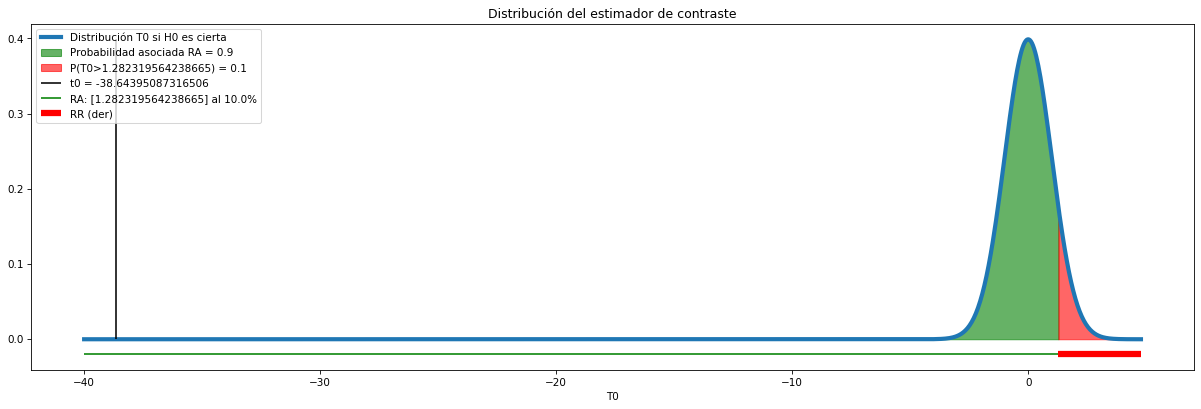

In [10]:
# Ahora representamos

# puntos para representar la distribución y las regiones de aceptación y rechazo
xmin = T0.ppf(0.000001)
xmax = T0.ppf(1-0.000001)
xs = np.linspace(-40, xmax, 1000)
xRA = np.linspace(xmin, t_crit_de, 1000)
xRRde = np.linspace(t_crit_de, xmax, 1000)

plt.figure(1, figsize=(20, 6))
plt.plot(xs, T0.pdf(xs), linewidth = 4, label=f'Distribución T0 si H0 es cierta')

plt.fill_between( xRA, T0.pdf(xRA), color="green", alpha=0.6, label=f'Probabilidad asociada RA = {1-alfa}')
plt.fill_between( xRRde, T0.pdf(xRRde), color="red", alpha=0.6, label=f'P(T0>{t_crit_de}) = {alfa}')

plt.vlines(t0, 0, np.max(T0.pdf(xs)), color='black', label=f't0 = {t0}')
plt.hlines(-0.02, -40, t_crit_de, color='green', label = f'RA: [{t_crit_de}] al {alfa*100}%')
plt.hlines(-0.02, t_crit_de, xmax, color='red', linewidth = 6, label = f'RR (der)')

plt.title('Distribución del estimador de contraste')
plt.xlabel('T0')
plt.legend()
plt.show()

In [11]:
# media poblacional que se quiere contrastar
mu_0 = 30

x_media = np.mean(x)
sx = np.std(x, ddof=1)

t0 = (x_media - mu_0) / (sx/np.sqrt(n))

# crea la distribución del estadístico de contraste
gl = n-1 # grados de libertad
T0 = stats.t(gl)

# calculamos el pvalor 
pvalor = T0.cdf(t0)

print(f'El valor observado del estadistico de contraste es {t0}, con un p-valor asociado igual a {pvalor}.')


# razonando con valores críticos
# nivel de significación
alfa = 0.1

# determina los valores críticos que definen la región de rechazo 
t_crit_iz = T0.ppf(alfa)

print(f'valor crítico (alfa={alfa}): {t_crit_iz}')

El valor observado del estadistico de contraste es -38.64395087316506, con un p-valor asociado igual a 1.4386291659634544e-207.
valor crítico (alfa=0.1): -1.2823195642386649


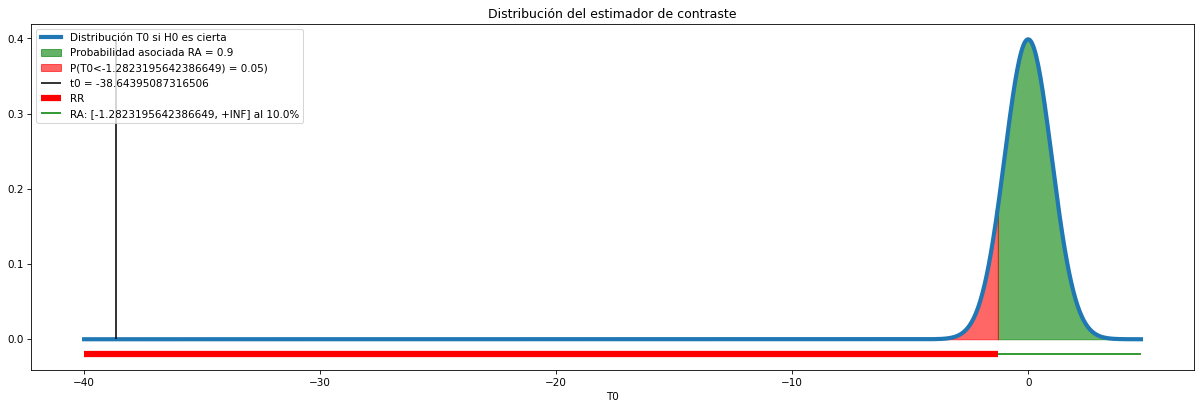

In [12]:
# Ahora representamos

# puntos para representar la distribución y las regiones de aceptación y rechazo
xmin = T0.ppf(0.000001)
xmax = T0.ppf(1-0.000001)
xs = np.linspace(-40, xmax, 1000)
xRA = np.linspace(t_crit_iz, xmax, 1000)
xRRiz = np.linspace(xmin, t_crit_iz, 1000)

plt.figure(1, figsize=(20, 6))
plt.plot(xs, T0.pdf(xs), linewidth = 4, label=f'Distribución T0 si H0 es cierta')

plt.fill_between( xRA, T0.pdf(xRA), color="green", alpha=0.6, label=f'Probabilidad asociada RA = {1-alfa}')
plt.fill_between( xRRiz, T0.pdf(xRRiz), color="red", alpha=0.6, label=f'P(T0<{t_crit_iz}) = {alfa/2})')

plt.vlines(t0, 0, np.max(T0.pdf(xs)), color='black', label=f't0 = {t0}')

plt.hlines(-0.02, -40, t_crit_iz, color='red', linewidth = 6, label = f'RR')
plt.hlines(-0.02, t_crit_iz, xmax, color='green', label = f'RA: [{t_crit_iz}, +INF] al {alfa*100}%')
plt.title('Distribución del estimador de contraste')
plt.xlabel('T0')
plt.legend()
plt.show()

## 2. Ajuste de las distribuciones de la irradiación, la temperatura y la precipitación en la celda 01

### 2.1. Mediante la aplicación del contraste de hipótesis de Kolmogorov-Smirnov (KS), con un nivel de significación del 3%, determinar si las variables de irradiación, temperatura y precipitación de cada trimestre en la celda 01 siguen una distribución normal. Apoyar la respuesta mediante qqplots.

In [13]:
variables = ['TEMP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_temp.MES == 12) | (df_orig_temp.MES == 1) | (df_orig_temp.MES == 2)
trim1 = df_orig_temp.loc[ind_filas, columnas]
print(trim1)

x1 = trim1.TEMP_CELDA01
n1 = len(x1)

      DIASEM  MES  ANNO  TEMP_CELDA01
0          2    1  2014     10.507935
1          3    1  2014     12.103457
2          4    1  2014     13.271104
3          5    1  2014      9.909261
4          6    1  2014      8.723439
...      ...  ...   ...           ...
4378       5   12  2025      6.387714
4379       6   12  2025      8.558502
4380       0   12  2025      6.722017
4381       1   12  2025      7.366825
4382       2   12  2025      7.053768

[1083 rows x 4 columns]


In [14]:
# nivel de significación
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(x1, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.0415299673111873 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


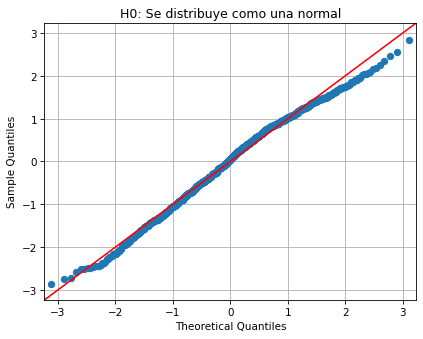

In [15]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(x1, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [16]:
mes_ini = 3
mes_fin = 5

variables = ['TEMP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_temp.MES >= mes_ini) & (df_orig_temp.MES <= mes_fin)
trim2 = df_orig_temp.loc[ind_filas, columnas]
print(trim2)

x2 = trim2.TEMP_CELDA01
n2 = len(x2)

      DIASEM  MES  ANNO  TEMP_CELDA01
59         5    3  2014     10.682709
60         6    3  2014     11.577128
61         0    3  2014      9.414113
62         1    3  2014      8.780823
63         2    3  2014     11.394816
...      ...  ...   ...           ...
4164       1    5  2025     24.716105
4165       2    5  2025     26.777822
4166       3    5  2025     28.192648
4167       4    5  2025     28.638540
4168       5    5  2025     28.331553

[1104 rows x 4 columns]


In [17]:
# nivel de significación
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(x2, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.053442802251356336 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


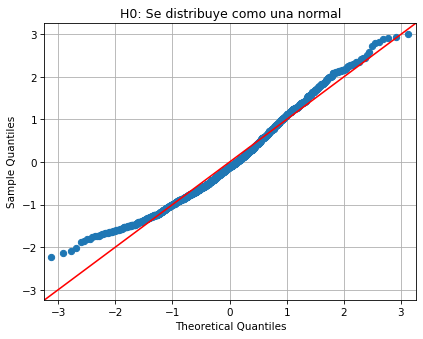

In [18]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(x2, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [19]:
mes_ini = 6
mes_fin = 8

variables = ['TEMP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_temp.MES >= mes_ini) & (df_orig_temp.MES <= mes_fin)
trim3 = df_orig_temp.loc[ind_filas, columnas]
print(trim3)

x3 = trim3.TEMP_CELDA01
n3 = len(x3)

      DIASEM  MES  ANNO  TEMP_CELDA01
151        6    6  2014     20.242218
152        0    6  2014     21.714142
153        1    6  2014     21.169403
154        2    6  2014     19.670319
155        3    6  2014     20.309082
...      ...  ...   ...           ...
4256       2    8  2025     23.928110
4257       3    8  2025     21.295950
4258       4    8  2025     21.871145
4259       5    8  2025     24.176290
4260       6    8  2025     21.349771

[1104 rows x 4 columns]


In [20]:
# nivel de significación
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(x3, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.05080506858746725 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


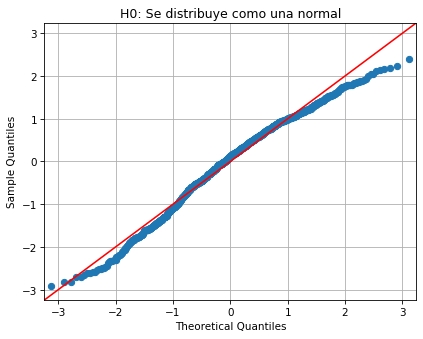

In [21]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(x3, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [22]:
mes_ini = 9
mes_fin = 11

variables = ['TEMP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_temp.MES >= mes_ini) & (df_orig_temp.MES <= mes_fin)
trim4 = df_orig_temp.loc[ind_filas, columnas]
print(trim4)

x4 = trim4.TEMP_CELDA01
n4 = len(x4)

      DIASEM  MES  ANNO  TEMP_CELDA01
243        0    9  2014     28.412231
244        1    9  2014     26.929413
245        2    9  2014     23.750895
246        3    9  2014     23.787802
247        4    9  2014     24.321860
...      ...  ...   ...           ...
4347       2   11  2025      8.628583
4348       3   11  2025      8.821780
4349       4   11  2025      9.128254
4350       5   11  2025      9.211963
4351       6   11  2025      9.672170

[1092 rows x 4 columns]


In [23]:
# nivel de significación
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(x4, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.0463323370420623 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


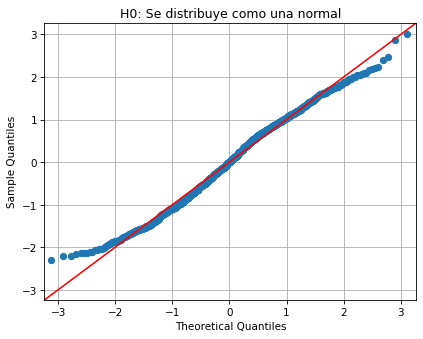

In [24]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(x4, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

### Irradiación

In [25]:
variables = ['IRRAD_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_irrad.MES == 12) | (df_orig_irrad.MES == 1) | (df_orig_irrad.MES == 2)
trim1i = df_orig_irrad.loc[ind_filas, columnas]
print(trim1i)

y1 = trim1i.IRRAD_CELDA01
ni1 = len(y1)

      DIASEM  MES  ANNO  IRRAD_CELDA01
0          2    1  2014      216153.55
1          3    1  2014       46182.44
2          4    1  2014      151202.60
3          5    1  2014      131521.06
4          6    1  2014      291939.72
...      ...  ...   ...            ...
4378       5   12  2025      219719.12
4379       6   12  2025      302196.90
4380       0   12  2025      349713.75
4381       1   12  2025      314719.75
4382       2   12  2025      415326.40

[1083 rows x 4 columns]


In [26]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(y1, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.0622240278292866 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


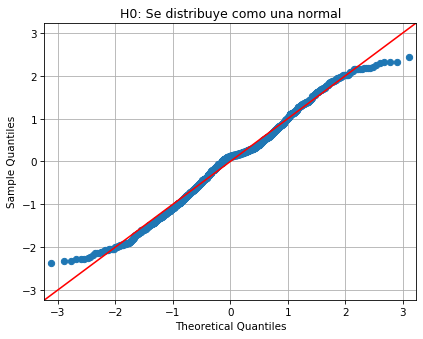

In [27]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(y1, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [28]:
mes_ini = 3
mes_fin = 5

variables = ['IRRAD_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_irrad.MES >= mes_ini) & (df_orig_irrad.MES <= mes_fin)
trim2i = df_orig_irrad.loc[ind_filas, columnas]
print(trim2i)

y2 = trim2i.IRRAD_CELDA01
ni2 = len(y2)

      DIASEM  MES  ANNO  IRRAD_CELDA01
59         5    3  2014      165354.31
60         6    3  2014      194038.30
61         0    3  2014      427012.90
62         1    3  2014      582443.20
63         2    3  2014      617432.06
...      ...  ...   ...            ...
4164       1    5  2025     1190132.10
4165       2    5  2025     1246565.40
4166       3    5  2025     1196513.60
4167       4    5  2025     1198144.50
4168       5    5  2025     1213384.00

[1104 rows x 4 columns]


In [29]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(y2, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.061101544520290374 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


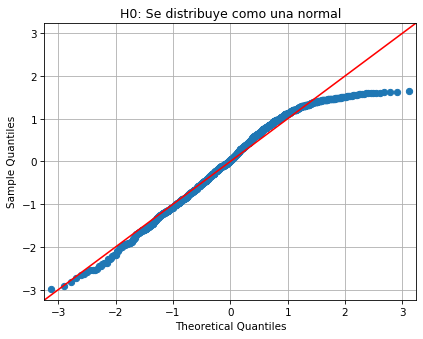

In [30]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(y2, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [31]:
mes_ini = 6
mes_fin = 8

variables = ['IRRAD_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_irrad.MES >= mes_ini) & (df_orig_irrad.MES <= mes_fin)
trim3i = df_orig_irrad.loc[ind_filas, columnas]
print(trim3i)

y3 = trim3i.IRRAD_CELDA01
ni3 = len(y3)

      DIASEM  MES  ANNO  IRRAD_CELDA01
151        6    6  2014      1191692.1
152        0    6  2014      1219360.0
153        1    6  2014      1273850.5
154        2    6  2014      1249459.1
155        3    6  2014      1172790.5
...      ...  ...   ...            ...
4256       2    8  2025      1072667.4
4257       3    8  2025      1035760.0
4258       4    8  2025      1020514.3
4259       5    8  2025      1038784.7
4260       6    8  2025       721134.7

[1104 rows x 4 columns]


In [32]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(y3, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.1351264588055917 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


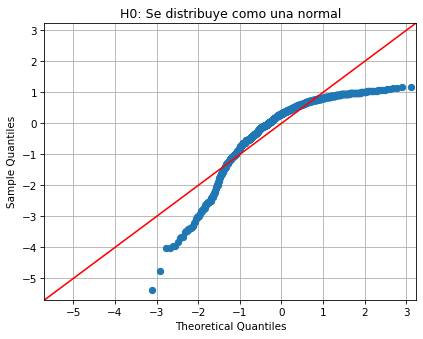

In [33]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(y3, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [34]:
mes_ini = 9
mes_fin = 11

variables = ['IRRAD_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_irrad.MES >= mes_ini) & (df_orig_irrad.MES <= mes_fin)
trim4i = df_orig_irrad.loc[ind_filas, columnas]
print(trim4i)

y4 = trim4i.IRRAD_CELDA01
ni4 = len(y4)

      DIASEM  MES  ANNO  IRRAD_CELDA01
243        0    9  2014     1016630.94
244        1    9  2014      905264.80
245        2    9  2014      994862.30
246        3    9  2014      998011.70
247        4    9  2014      992053.75
...      ...  ...   ...            ...
4347       2   11  2025      464901.00
4348       3   11  2025      460276.75
4349       4   11  2025      460586.97
4350       5   11  2025      356572.72
4351       6   11  2025      277167.78

[1092 rows x 4 columns]


In [35]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(y4, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.05226560103204292 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


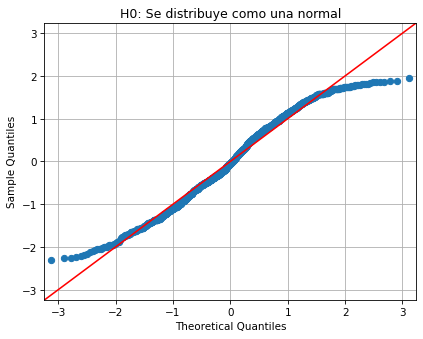

In [36]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(y4, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

### Precipitación

In [37]:
variables = ['PRECIP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_precip.MES == 12) | (df_orig_precip.MES == 1) | (df_orig_precip.MES == 2)
trim1p = df_orig_precip.loc[ind_filas, columnas]
print(trim1p)

z1 = trim1p.PRECIP_CELDA01
np1 = len(z1)

      DIASEM  MES  ANNO  PRECIP_CELDA01
0          2    1  2014    1.726640e-05
1          3    1  2014    1.975207e-04
2          4    1  2014    1.714909e-04
3          5    1  2014    3.041076e-04
4          6    1  2014    4.802520e-07
...      ...  ...   ...             ...
4378       5   12  2025    2.070589e-04
4379       6   12  2025    3.717894e-05
4380       0   12  2025    1.091532e-05
4381       1   12  2025    2.449622e-05
4382       2   12  2025    8.997887e-08

[1083 rows x 4 columns]


In [38]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(z1, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.3439808751663842 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


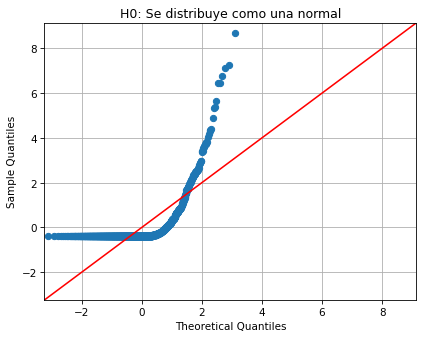

In [39]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(z1, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [40]:
mes_ini = 3
mes_fin = 5

variables = ['PRECIP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_precip.MES >= mes_ini) & (df_orig_precip.MES <= mes_fin)
trim2p = df_orig_precip.loc[ind_filas, columnas]
print(trim2p)

z2 = trim2p.PRECIP_CELDA01
np2 = len(z2)

      DIASEM  MES  ANNO  PRECIP_CELDA01
59         5    3  2014    2.949543e-04
60         6    3  2014    1.295314e-04
61         0    3  2014    3.636272e-05
62         1    3  2014    2.056671e-07
63         2    3  2014    2.363913e-05
...      ...  ...   ...             ...
4164       1    5  2025    3.588696e-08
4165       2    5  2025    0.000000e+00
4166       3    5  2025    3.686485e-09
4167       4    5  2025    9.313226e-10
4168       5    5  2025    3.607029e-08

[1104 rows x 4 columns]


In [41]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(z2, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.3313649007422911 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


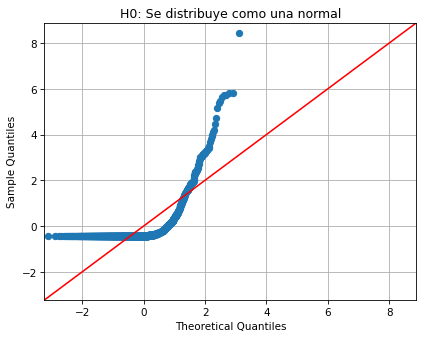

In [42]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(z2, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [43]:
mes_ini = 6
mes_fin = 8

variables = ['PRECIP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_precip.MES >= mes_ini) & (df_orig_precip.MES <= mes_fin)
trim3p = df_orig_precip.loc[ind_filas, columnas]
print(trim3p)

z3 = trim3p.PRECIP_CELDA01
np3 = len(z3)

      DIASEM  MES  ANNO  PRECIP_CELDA01
151        6    6  2014    7.262035e-08
152        0    6  2014    3.588696e-08
153        1    6  2014    5.413478e-08
154        2    6  2014    3.605140e-08
155        3    6  2014    3.591099e-08
...      ...  ...   ...             ...
4256       2    8  2025    0.000000e+00
4257       3    8  2025    5.873541e-08
4258       4    8  2025    7.236971e-08
4259       5    8  2025    7.199625e-08
4260       6    8  2025    6.753000e-06

[1104 rows x 4 columns]


In [44]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(z3, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.4230801092232159 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


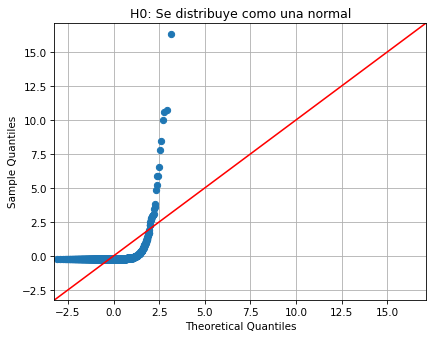

In [45]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(z3, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

In [46]:
mes_ini = 9
mes_fin = 11

variables = ['PRECIP_CELDA01']
columnas = ['DIASEM','MES', 'ANNO'] + variables

ind_filas = (df_orig_precip.MES >= mes_ini) & (df_orig_precip.MES <= mes_fin)
trim4p = df_orig_precip.loc[ind_filas, columnas]
print(trim4p)

z4 = trim4p.PRECIP_CELDA01
np4 = len(z4)

      DIASEM  MES  ANNO  PRECIP_CELDA01
243        0    9  2014    5.353384e-08
244        1    9  2014    2.650367e-05
245        2    9  2014    1.165084e-07
246        3    9  2014    3.560777e-08
247        4    9  2014    9.015199e-08
...      ...  ...   ...             ...
4347       2   11  2025    0.000000e+00
4348       3   11  2025    5.461527e-08
4349       4   11  2025    1.840615e-08
4350       5   11  2025    9.740336e-05
4351       6   11  2025    6.473457e-05

[1092 rows x 4 columns]


In [47]:
alfa = 0.03

# realiza el test
ks = sm.stats.diagnostic.kstest_normal(z4, dist='norm', pvalmethod='table')

max_d   = ks[0]
p_valor = ks[1]
print(f'Contraste KS es una normal:: máxima distancia observada = {max_d} -> p_valor = {p_valor}')

# concluye
print(f'Como el pvalor < {alfa}, se puede rechazar H0 con un nivel de significación del {alfa*100}% ya que la distancia máxima observada es suficientemente grande.')
print(f'Según el test no paramétrico KS se puede afirmar, con un nivel de significación del {alfa*100}%, que los datos de la muestra no siguen una distribución normal.')

Contraste KS es una normal:: máxima distancia observada = 0.36145669422048005 -> p_valor = 0.0009999999999998899
Como el pvalor < 0.03, se puede rechazar H0 con un nivel de significación del 3.0% ya que la distancia máxima observada es suficientemente grande.
Según el test no paramétrico KS se puede afirmar, con un nivel de significación del 3.0%, que los datos de la muestra no siguen una distribución normal.


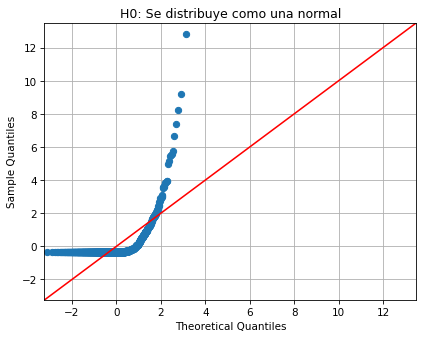

In [48]:
# nombre de la distribución teórica que se contrasta (norm, uniform, triang, expon, ...)
distribucion_teo = stats.norm

# genera qqplot de la variable x
sm.qqplot(z4, line='45', fit=True, dist=distribucion_teo)
plt.title('H0: Se distribuye como una normal')
plt.grid(); plt.show()

### 2.2. Para las variables de irradiación, temperatura y precipitación de la celda 01 (sin separar por trimestres), ajustar, por un lado, las siguientes distribuciones teóricas: uniforme, exponencial, normal, beta y triangular, y por otro lado, un kernel. Para cada variable, representar todas las distribuciones en una misma gráfica y discutir qué distribución escoger en cada caso, teniendo en cuenta el sentido físico de la variable y la complejidad de la distribución ajustada.

#### TEMPERATURA

In [49]:
# .dropna() elimina los valores nulos y .values lo transforma en array
x = df_orig_temp['TEMP_CELDA01'].dropna().values
n = len(x)

uniform :: 	 logLikelihood_med = -3.4661186357981073 	 params:(2.6335132, 32.0122498)
expon :: 	 logLikelihood_med = -3.6813784725813448 	 params:(2.6335132, 14.605212310654807)
norm :: 	 logLikelihood_med = -3.364547307082515 	 params:(17.238725510654806, 6.997890691620261)
triang :: 	 logLikelihood_med = -3.296389252939863 	 params:(0.2867004930256089, 2.6117616848936596, 32.49321302320048)
beta :: 	 logLikelihood_med = -3.301264399003069 	 params:(2.0843042981650592, 2.497674323005951, 2.5991650997714126, 32.39022748323486)


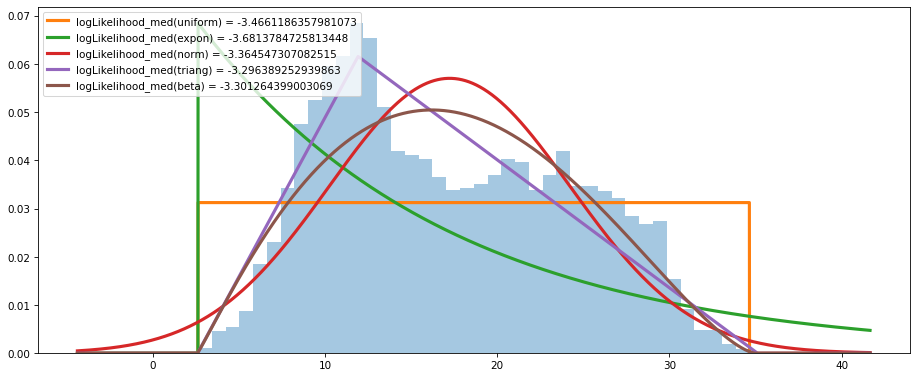

,Distribución,Media verosimilitud log,Parámetros
0,expon,-3.681378,"(2.6335132, 14.605212310654807)"
1,uniform,-3.466119,"(2.6335132, 32.0122498)"
2,norm,-3.364547,"(17.238725510654806, 6.997890691620261)"
3,beta,-3.301264,"(2.0843042981650592, 2.497674323005951, 2.5991..."
4,triang,-3.296389,"(0.2867004930256089, 2.6117616848936596, 32.49..."


In [50]:
# Indica la lista de distribuciones continuas que se prueban (ojo, puede tardar)
dist_names = ['uniform', 'expon', 'norm', 'triang', 'beta']
xs = np.linspace(min(x)-np.std(x),max(x)+np.std(x), 5000)
    
plt.figure(1, figsize=(15, 6))
plt.hist(x, bins=40, density = True, alpha = 0.4)
    
# crea contendor con los resultados para elegir al final
res_aju_distr = []
    
for dist_name in dist_names:
    dist = getattr(stats, dist_name)
    params = dist.fit(x)
    arg = params[:-2]
    loc = params[-2]
    scale = params[-1]
    
    if arg:
        pdf_fitted = dist.pdf(xs, *arg, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(x, *arg, loc=loc, scale=scale)) / n
    else:
        pdf_fitted = dist.pdf(xs, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(x, loc=loc, scale=scale)) / n

    # guarda resultado para mostrarlo al final
    res_aju_distr.append((dist_name, logLikelihood_med, params))
        
    print(f'{dist_name} :: \t logLikelihood_med = {logLikelihood_med} \t params:{params}')
    plt.plot(xs, pdf_fitted, linewidth = 3, label=f'logLikelihood_med({dist_name}) = {logLikelihood_med}' )
    
plt.legend(loc='upper left')
plt.show()


# tabla de resultados, ordenada de peor a mejor según logLikelihood_med
res_aju_distr_ord = sorted(res_aju_distr, key=lambda x:x[1])
res_dftemp4 = pd.DataFrame(res_aju_distr_ord, columns = ['Distribución', 'Media verosimilitud log', 'Parámetros'])
res_dftemp4

Verosimilitud logarítmica media de KDE: -3.2678690273286617


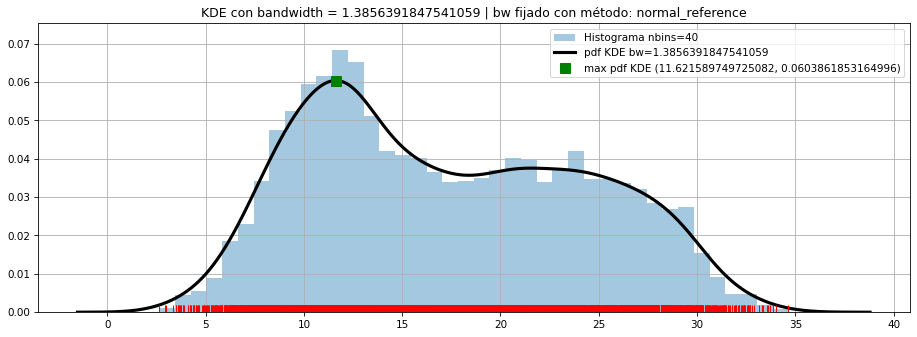

In [51]:
# estima el KDE

# fija la función kernel a utilizar
# “gau” for Gaussian,  “epa” for Epanechnikov, “uni” for uniform
# “tri” for triangular, “cos” for cosine,  “biw” for biweight,  “triw” for triweight
kernel_fun = 'gau'

# fija el bandwidth (si auto lo estima la función de ajuste)
tipo_bw = 'auto' # 'manual'

if tipo_bw == 'auto':
    bandwidth = 'normal_reference' # otras opciones: bandwidth = 'scott', bandwidth = 'silverman'
else:
    bandwidth = 0.6 # fija bandwidth exacto

    
# estima kde
kde = KDEUnivariate(x)
kde.fit(kernel = kernel_fun, bw = bandwidth, fft = True)

# calcula verosimilitud log media de ambas aproximaciones
logLikelihood_med_kde = np.sum(np.log(kde.evaluate(x))) / n

print(f'Verosimilitud logarítmica media de KDE: {logLikelihood_med_kde}')

# fija nbins para mostrar histograma
nbins_hist = 40

plt.figure(1, figsize=(15, 5))
plt.hist(x, nbins_hist, density = True, alpha = 0.4, label =f'Histograma nbins={nbins_hist}')
plt.plot(kde.support, kde.density, color = 'black', linewidth = 3, label =f'pdf KDE bw={kde.bw}')

# marca el máximo
index_max_pdf = np.argmax(kde.density)   # <--- encuentra el argumento que hace máximo la función
x_max_pdf = kde.support[index_max_pdf]
max_pdf = kde.density[index_max_pdf]
plt.plot(x_max_pdf, max_pdf, 's', color = 'green', markersize = 10, label =f'max pdf KDE ({x_max_pdf}, {max_pdf})')

sns.rugplot(x, height = 0.025, lw = 0.4, color = 'red')
plt.title(f'KDE con bandwidth = {kde.bw} | bw fijado con método: {kde.bw_method}')
plt.grid(); plt.legend()
plt.show()

uniform :: 	 logLikelihood_med = -3.4661186357981073 	 params:(2.6335132, 32.0122498)
expon :: 	 logLikelihood_med = -3.6813784725813448 	 params:(2.6335132, 14.605212310654807)
norm :: 	 logLikelihood_med = -3.364547307082515 	 params:(17.238725510654806, 6.997890691620261)
triang :: 	 logLikelihood_med = -3.296389252939863 	 params:(0.2867004930256089, 2.6117616848936596, 32.49321302320048)
beta :: 	 logLikelihood_med = -3.301264399003069 	 params:(2.0843042981650592, 2.497674323005951, 2.5991650997714126, 32.39022748323486)


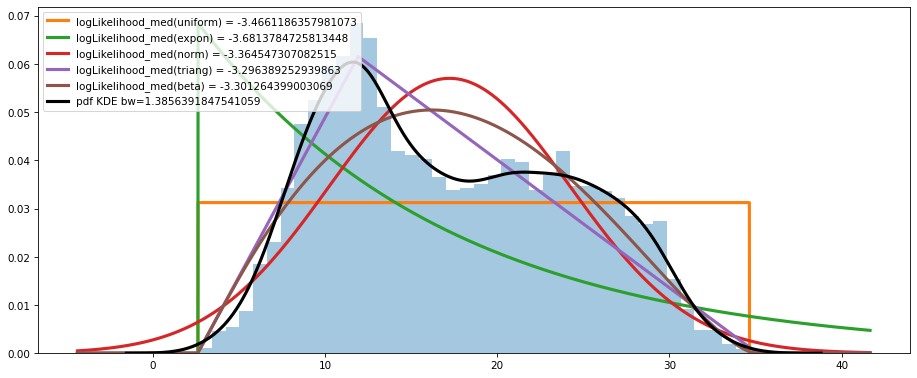

In [52]:
dist_names = ['uniform', 'expon', 'norm', 'triang', 'beta']
xs = np.linspace(min(x)-np.std(x),max(x)+np.std(x), 5000)  
plt.figure(1, figsize=(15, 6))
plt.hist(x, bins=40, density = True, alpha = 0.4)

for dist_name in dist_names:
    dist = getattr(stats, dist_name)
    params = dist.fit(x)
    arg = params[:-2]
    loc = params[-2]
    scale = params[-1]
    
    if arg:
        pdf_fitted = dist.pdf(xs, *arg, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(x, *arg, loc=loc, scale=scale)) / n
    else:
        pdf_fitted = dist.pdf(xs, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(x, loc=loc, scale=scale)) / n

    # guarda resultado para mostrarlo al final
    res_aju_distr.append((dist_name, logLikelihood_med, params))
        
    print(f'{dist_name} :: \t logLikelihood_med = {logLikelihood_med} \t params:{params}')
    plt.plot(xs, pdf_fitted, linewidth = 3, label=f'logLikelihood_med({dist_name}) = {logLikelihood_med}' )

plt.plot(kde.support, kde.density, color = 'black', linewidth = 3, label =f'pdf KDE bw={kde.bw}')
plt.legend(loc='upper left')
plt.show()

#### IRRADIACIÓN

In [53]:
# .dropna() elimina los valores nulos y .values lo transforma en array
y = df_orig_irrad['IRRAD_CELDA01'].dropna().values
n = len(y)

uniform :: 	 logLikelihood_med = -14.057723715038831 	 params:(33012.16, 1274065.74)
expon :: 	 logLikelihood_med = -14.478320929000441 	 params:(33012.16, 713773.4749441022)
norm :: 	 logLikelihood_med = -14.171873489283927 	 params:(746785.6349441023, 345564.626252246)
triang :: 	 logLikelihood_med = -14.057496270282462 	 params:(0.9706614178031077, -124106.45808890619, 1432898.261514247)
beta :: 	 logLikelihood_med = -14.020819728491313 	 params:(1.2581471838867602, 0.9757551064735592, 32784.68771288698, 1274293.212287113)


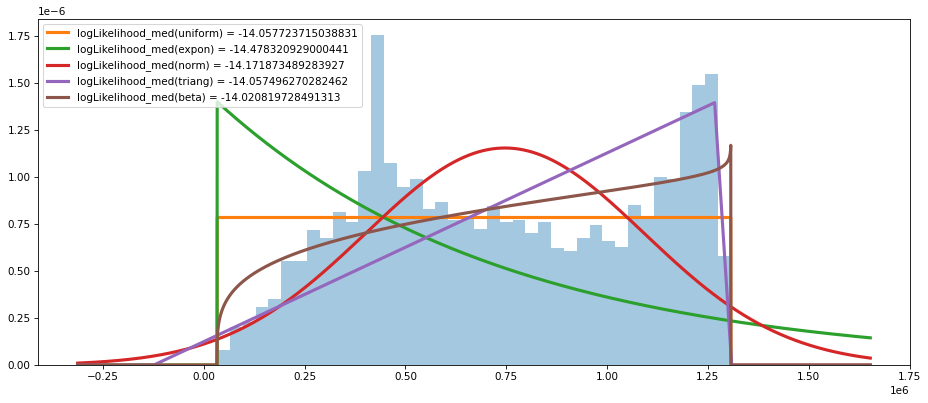

,Distribución,Media verosimilitud log,Parámetros
0,expon,-14.478321,"(33012.16, 713773.4749441022)"
1,norm,-14.171873,"(746785.6349441023, 345564.626252246)"
2,uniform,-14.057724,"(33012.16, 1274065.74)"
3,triang,-14.057496,"(0.9706614178031077, -124106.45808890619, 1432..."
4,beta,-14.020820,"(1.2581471838867602, 0.9757551064735592, 32784..."


In [54]:
# Indica la lista de distribuciones continuas que se prueban (ojo, puede tardar)
dist_names = ['uniform', 'expon', 'norm', 'triang', 'beta']
xs = np.linspace(min(y)-np.std(y),max(y)+np.std(y), 5000)
    
plt.figure(1, figsize=(15, 6))
plt.hist(y, bins=40, density = True, alpha = 0.4)
    
# crea contendor con los resultados para elegir al final
res_aju_distr = []
    
for dist_name in dist_names:
    dist = getattr(stats, dist_name)
    params = dist.fit(y)
    arg = params[:-2]
    loc = params[-2]
    scale = params[-1]
    
    if arg:
        pdf_fitted = dist.pdf(xs, *arg, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(y, *arg, loc=loc, scale=scale)) / n
    else:
        pdf_fitted = dist.pdf(xs, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(y, loc=loc, scale=scale)) / n

    # guarda resultado para mostrarlo al final
    res_aju_distr.append((dist_name, logLikelihood_med, params))
        
    print(f'{dist_name} :: \t logLikelihood_med = {logLikelihood_med} \t params:{params}')
    plt.plot(xs, pdf_fitted, linewidth = 3, label=f'logLikelihood_med({dist_name}) = {logLikelihood_med}' )
    
plt.legend(loc='upper left')
plt.show()


# tabla de resultados, ordenada de peor a mejor según logLikelihood_med
res_aju_distr_ord = sorted(res_aju_distr, key=lambda y:y[1])
res_dfirrd_4 = pd.DataFrame(res_aju_distr_ord, columns = ['Distribución', 'Media verosimilitud log', 'Parámetros'])
res_dfirrd_4

Verosimilitud logarítmica media de KDE: -14.011357164204743


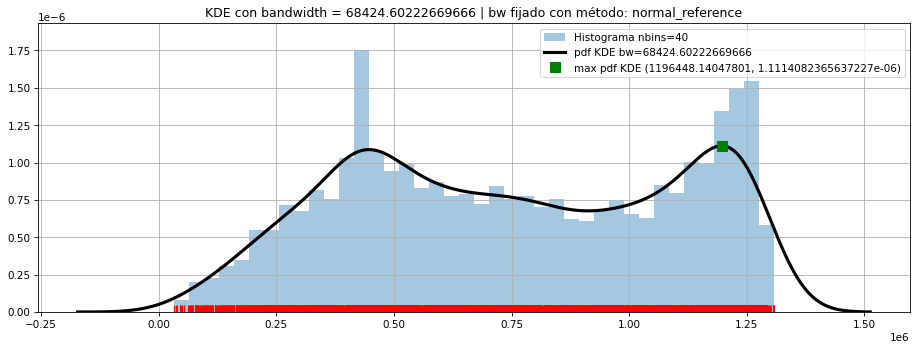

In [55]:
# estima el KDE

# fija la función kernel a utilizar
# “gau” for Gaussian,  “epa” for Epanechnikov, “uni” for uniform
# “tri” for triangular, “cos” for cosine,  “biw” for biweight,  “triw” for triweight
kernel_fun = 'gau'

# fija el bandwidth (si auto lo estima la función de ajuste)
tipo_bw = 'auto' # 'manual'

if tipo_bw == 'auto':
    bandwidth = 'normal_reference' # otras opciones: bandwidth = 'scott', bandwidth = 'silverman'
else:
    bandwidth = 0.6 # fija bandwidth exacto

    
# estima kde
kde = KDEUnivariate(y)
kde.fit(kernel = kernel_fun, bw = bandwidth, fft = True)

# calcula verosimilitud log media de ambas aproximaciones
logLikelihood_med_kde = np.sum(np.log(kde.evaluate(y))) / n

print(f'Verosimilitud logarítmica media de KDE: {logLikelihood_med_kde}')

# fija nbins para mostrar histograma
nbins_hist = 40

plt.figure(1, figsize=(15, 5))
plt.hist(y, nbins_hist, density = True, alpha = 0.4, label =f'Histograma nbins={nbins_hist}')
plt.plot(kde.support, kde.density, color = 'black', linewidth = 3, label =f'pdf KDE bw={kde.bw}')

# marca el máximo
index_max_pdf = np.argmax(kde.density)   # <--- encuentra el argumento que hace máximo la función
y_max_pdf = kde.support[index_max_pdf]
max_pdf = kde.density[index_max_pdf]
plt.plot(y_max_pdf, max_pdf, 's', color = 'green', markersize = 10, label =f'max pdf KDE ({y_max_pdf}, {max_pdf})')

sns.rugplot(y, height = 0.025, lw = 0.4, color = 'red')
plt.title(f'KDE con bandwidth = {kde.bw} | bw fijado con método: {kde.bw_method}')
plt.grid(); plt.legend()
plt.show()

uniform :: 	 logLikelihood_med = -14.057723715038831 	 params:(33012.16, 1274065.74)
expon :: 	 logLikelihood_med = -14.478320929000441 	 params:(33012.16, 713773.4749441022)
norm :: 	 logLikelihood_med = -14.171873489283927 	 params:(746785.6349441023, 345564.626252246)
triang :: 	 logLikelihood_med = -14.057496270282462 	 params:(0.9706614178031077, -124106.45808890619, 1432898.261514247)
beta :: 	 logLikelihood_med = -14.020819728491313 	 params:(1.2581471838867602, 0.9757551064735592, 32784.68771288698, 1274293.212287113)


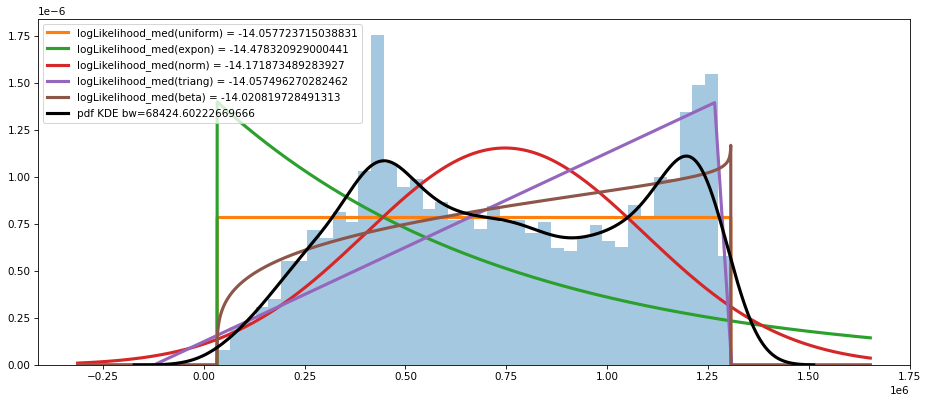

In [56]:
dist_names = ['uniform', 'expon', 'norm', 'triang', 'beta']
xs = np.linspace(min(y)-np.std(y),max(y)+np.std(y), 5000)  
plt.figure(1, figsize=(15, 6))
plt.hist(y, bins=40, density = True, alpha = 0.4)

for dist_name in dist_names:
    dist = getattr(stats, dist_name)
    params = dist.fit(y)
    arg = params[:-2]
    loc = params[-2]
    scale = params[-1]
    
    if arg:
        pdf_fitted = dist.pdf(xs, *arg, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(y, *arg, loc=loc, scale=scale)) / n
    else:
        pdf_fitted = dist.pdf(xs, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(y, loc=loc, scale=scale)) / n

    # guarda resultado para mostrarlo al final
    res_aju_distr.append((dist_name, logLikelihood_med, params))
        
    print(f'{dist_name} :: \t logLikelihood_med = {logLikelihood_med} \t params:{params}')
    plt.plot(xs, pdf_fitted, linewidth = 3, label=f'logLikelihood_med({dist_name}) = {logLikelihood_med}' )

plt.plot(kde.support, kde.density, color = 'black', linewidth = 3, label =f'pdf KDE bw={kde.bw}')
plt.legend(loc='upper left')
plt.show()

#### PRECIPITACIÓN

In [57]:
# .dropna() elimina los valores nulos y .values lo transforma en array
z = df_orig_precip['PRECIP_CELDA01'].dropna().values
n = len(z)

uniform :: 	 logLikelihood_med = 5.889573270306235 	 params:(0.0, 0.0027681577)
expon :: 	 logLikelihood_med = 8.725601398503239 	 params:(0.0, 5.973446514666451e-05)
norm :: 	 logLikelihood_med = 7.244783480687859 	 params:(5.973446514666451e-05, 0.00017274016759581562)
triang :: 	 logLikelihood_med = 6.406623455499837 	 params:(0.1392014265612232, -0.00044774589733923595, 0.0032166537540464627)


/usr/local/lib/python3.8/dist-packages/scipy/stats/_continuous_distns.py:709: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.8/dist-packages/scipy/optimize/_minpack_py.py:178: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


beta :: 	 logLikelihood_med = 14.214907918560089 	 params:(0.34241336415588225, 241.90221901251806, -5.953026098521149e-30, 0.006887537750707917)


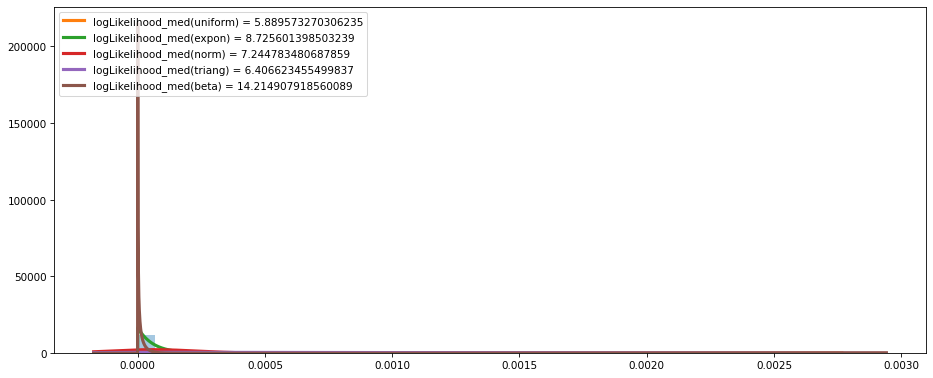

,Distribución,Media verosimilitud log,Parámetros
0,uniform,5.889573,"(0.0, 0.0027681577)"
1,triang,6.406623,"(0.1392014265612232, -0.00044774589733923595, ..."
2,norm,7.244783,"(5.973446514666451e-05, 0.00017274016759581562)"
3,expon,8.725601,"(0.0, 5.973446514666451e-05)"
4,beta,14.214908,"(0.34241336415588225, 241.90221901251806, -5.9..."


In [58]:
# Indica la lista de distribuciones continuas que se prueban (ojo, puede tardar)
dist_names = ['uniform', 'expon', 'norm', 'triang', 'beta']
xs = np.linspace(min(z)-np.std(z),max(z)+np.std(z), 5000)
    
plt.figure(1, figsize=(15, 6))
plt.hist(z, bins=40, density = True, alpha = 0.4)
    
# crea contendor con los resultados para elegir al final
res_aju_distr = []
    
for dist_name in dist_names:
    dist = getattr(stats, dist_name)
    params = dist.fit(z)
    arg = params[:-2]
    loc = params[-2]
    scale = params[-1]
    
    if arg:
        pdf_fitted = dist.pdf(xs, *arg, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(z, *arg, loc=loc, scale=scale)) / n
    else:
        pdf_fitted = dist.pdf(xs, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(z, loc=loc, scale=scale)) / n

    # guarda resultado para mostrarlo al final
    res_aju_distr.append((dist_name, logLikelihood_med, params))
        
    print(f'{dist_name} :: \t logLikelihood_med = {logLikelihood_med} \t params:{params}')
    plt.plot(xs, pdf_fitted, linewidth = 3, label=f'logLikelihood_med({dist_name}) = {logLikelihood_med}' )
    
plt.legend(loc='upper left')
plt.show()


# tabla de resultados, ordenada de peor a mejor según logLikelihood_med
res_aju_distr_ord = sorted(res_aju_distr, key=lambda y:y[1])
res_dfprecip4 = pd.DataFrame(res_aju_distr_ord, columns = ['Distribución', 'Media verosimilitud log', 'Parámetros'])
res_dfprecip4

Verosimilitud logarítmica media de KDE: 9.94223241986368


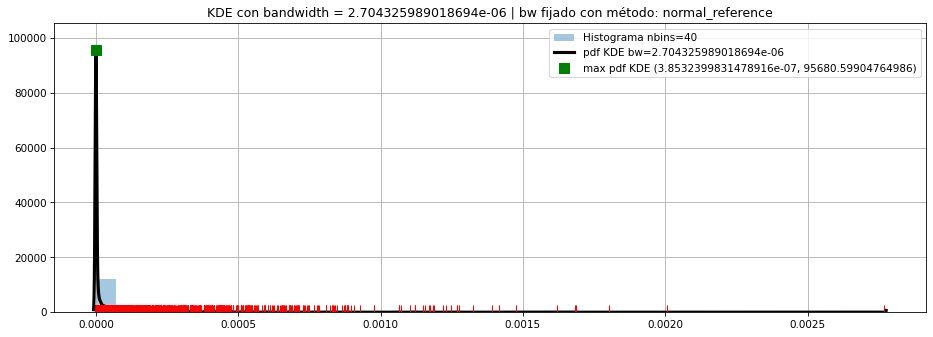

In [59]:
# estima el KDE

# fija la función kernel a utilizar
# “gau” for Gaussian,  “epa” for Epanechnikov, “uni” for uniform
# “tri” for triangular, “cos” for cosine,  “biw” for biweight,  “triw” for triweight
kernel_fun = 'gau'

# fija el bandwidth (si auto lo estima la función de ajuste)
tipo_bw = 'auto' # 'manual'

if tipo_bw == 'auto':
    bandwidth = 'normal_reference' # otras opciones: bandwidth = 'scott', bandwidth = 'silverman'
else:
    bandwidth = 0.6 # fija bandwidth exacto

    
# estima kde
kde = KDEUnivariate(z)
kde.fit(kernel = kernel_fun, bw = bandwidth, fft = True)

# calcula verosimilitud log media de ambas aproximaciones
logLikelihood_med_kde = np.sum(np.log(kde.evaluate(z))) / n

print(f'Verosimilitud logarítmica media de KDE: {logLikelihood_med_kde}')

# fija nbins para mostrar histograma
nbins_hist = 40

plt.figure(1, figsize=(15, 5))
plt.hist(z, nbins_hist, density = True, alpha = 0.4, label =f'Histograma nbins={nbins_hist}')
plt.plot(kde.support, kde.density, color = 'black', linewidth = 3, label =f'pdf KDE bw={kde.bw}')

# marca el máximo
index_max_pdf = np.argmax(kde.density)   # <--- encuentra el argumento que hace máximo la función
z_max_pdf = kde.support[index_max_pdf]
max_pdf = kde.density[index_max_pdf]
plt.plot(z_max_pdf, max_pdf, 's', color = 'green', markersize = 10, label =f'max pdf KDE ({z_max_pdf}, {max_pdf})')

sns.rugplot(z, height = 0.025, lw = 0.4, color = 'red')
plt.title(f'KDE con bandwidth = {kde.bw} | bw fijado con método: {kde.bw_method}')
plt.grid(); plt.legend()
plt.show()

uniform :: 	 logLikelihood_med = 5.889573270306235 	 params:(0.0, 0.0027681577)
expon :: 	 logLikelihood_med = 8.725601398503239 	 params:(0.0, 5.973446514666451e-05)
norm :: 	 logLikelihood_med = 7.244783480687859 	 params:(5.973446514666451e-05, 0.00017274016759581562)
triang :: 	 logLikelihood_med = 6.406623455499837 	 params:(0.1392014265612232, -0.00044774589733923595, 0.0032166537540464627)


/usr/local/lib/python3.8/dist-packages/scipy/stats/_continuous_distns.py:709: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.8/dist-packages/scipy/optimize/_minpack_py.py:178: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


beta :: 	 logLikelihood_med = 14.214907918560089 	 params:(0.34241336415588225, 241.90221901251806, -5.953026098521149e-30, 0.006887537750707917)


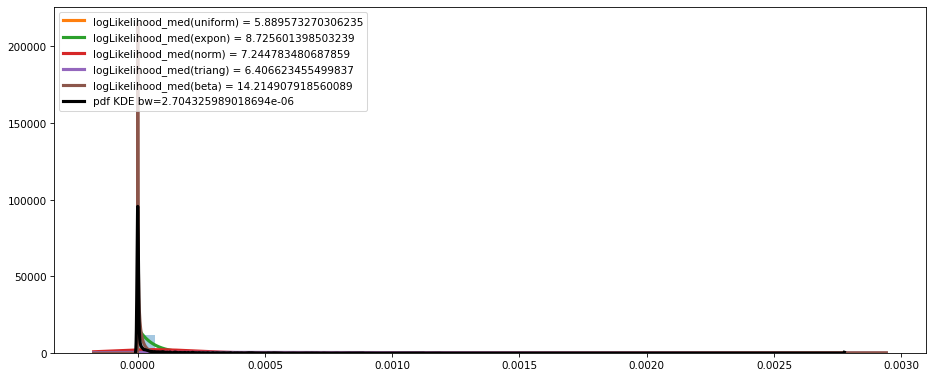

In [60]:
dist_names = ['uniform', 'expon', 'norm', 'triang', 'beta']
xs = np.linspace(min(z)-np.std(z),max(z)+np.std(z), 5000)  
plt.figure(1, figsize=(15, 6))
plt.hist(z, bins=40, density = True, alpha = 0.4)

for dist_name in dist_names:
    dist = getattr(stats, dist_name)
    params = dist.fit(z)
    arg = params[:-2]
    loc = params[-2]
    scale = params[-1]
    
    if arg:
        pdf_fitted = dist.pdf(xs, *arg, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(z, *arg, loc=loc, scale=scale)) / n
    else:
        pdf_fitted = dist.pdf(xs, loc=loc, scale=scale)
        logLikelihood_med = np.sum(dist.logpdf(z, loc=loc, scale=scale)) / n

    # guarda resultado para mostrarlo al final
    res_aju_distr.append((dist_name, logLikelihood_med, params))
        
    print(f'{dist_name} :: \t logLikelihood_med = {logLikelihood_med} \t params:{params}')
    plt.plot(xs, pdf_fitted, linewidth = 3, label=f'logLikelihood_med({dist_name}) = {logLikelihood_med}' )

plt.plot(kde.support, kde.density, color = 'black', linewidth = 3, label =f'pdf KDE bw={kde.bw}')
plt.legend(loc='upper left')
plt.show()

## 3. Comparación de las medias trimestrales de la irradiación, la temperatura y la precipitación en la celda 01.

### 3.1. Calcular los intervalos de confianza para la media de los datos de irradiación de la celda 01 por trimestres mediante Bootstrap, con un nivel de confianza del 50% y del 99%. ¿Para qué pares de trimestres se solapan sus respectivos intervalos de confianza? ¿La respuesta a la pregunta anterior depende del nivel de confianza? 

#### Trimestre 1

In [61]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y1,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [392950.833296369, 399198.5515225817]
Error estándar del estimador media muestral, estimado según método BCa: 4643.770098941795


In [62]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y1,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [383965.1660951093, 407922.9460476188]
Error estándar del estimador media muestral, estimado según método BCa: 4643.770098941795


#### Trimestre 2

In [63]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y2,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [852516.3517217505, 863003.3041807255]
Error estándar del estimador media muestral, estimado según método BCa: 7871.1720926339995


In [64]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y2,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [837038.0863055476, 878369.0210422032]
Error estándar del estimador media muestral, estimado según método BCa: 7871.1720926339995


#### Trimestre 3

In [65]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y3,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [1131566.9701121878, 1137721.771845808]
Error estándar del estimador media muestral, estimado según método BCa: 4556.388112022478


In [66]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y3,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [1122379.162450827, 1146024.457572501]
Error estándar del estimador media muestral, estimado según método BCa: 4556.388112022478


#### Trimestre 4

In [67]:
muestra_orig = (y4,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [585698.1346586486, 595050.549909428]
Error estándar del estimador media muestral, estimado según método BCa: 7045.029187825143


In [68]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (y4,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [572062.8638015758, 608596.5213603701]
Error estándar del estimador media muestral, estimado según método BCa: 7045.029187825143


### TEMPERATURA

#### Trimestre 1

In [69]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x1,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [9.715064346293413, 9.816820756149223]
Error estándar del estimador media muestral, estimado según método BCa: 0.07618031902251196


In [70]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x1,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [9.568538475670415, 9.957237516582204]
Error estándar del estimador media muestral, estimado según método BCa: 0.07618031902251196


#### Trimestre 2

In [71]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x2,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [15.263511796605307, 15.44543719144298]
Error estándar del estimador media muestral, estimado según método BCa: 0.13316617928119082


In [72]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x2,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [15.01890483462041, 15.696865634573387]
Error estándar del estimador media muestral, estimado según método BCa: 0.13316617928119082


#### Trimestre 3

In [73]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x3,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [25.55199401299351, 25.703231605978086]
Error estándar del estimador media muestral, estimado según método BCa: 0.11312467055057455


In [74]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x3,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [25.33298397332061, 25.91040218045835]
Error estándar del estimador media muestral, estimado según método BCa: 0.11312467055057455


#### Trimestre 4

In [75]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x4,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [17.966701141373736, 18.1736434688901]
Error estándar del estimador media muestral, estimado según método BCa: 0.1528270298157358


In [76]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (x4,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [17.666259220673563, 18.464343587880624]
Error estándar del estimador media muestral, estimado según método BCa: 0.1528270298157358


### PRECIPITACIÓN

#### Trimestre 1

In [77]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z1,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [7.083949151740687e-05, 7.837169401198248e-05]
Error estándar del estimador media muestral, estimado según método BCa: 5.620899274082315e-06


In [78]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z1,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [6.143426662527165e-05, 9.144829772495359e-05]
Error estándar del estimador media muestral, estimado según método BCa: 5.620899274082315e-06


#### Trimestre 2

In [79]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z2,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [7.902163145981498e-05, 8.672957437033684e-05]
Error estándar del estimador media muestral, estimado según método BCa: 5.712295620545301e-06


In [80]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z2,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [6.974072947637349e-05, 9.929681365486671e-05]
Error estándar del estimador media muestral, estimado según método BCa: 5.712295620545301e-06


#### Trimestre 3

In [81]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z3,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [7.002362669667491e-06, 8.627648779547257e-06]
Error estándar del estimador media muestral, estimado según método BCa: 1.2045617885286182e-06


In [82]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z3,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [5.327695112194817e-06, 1.1585080478682497e-05]
Error estándar del estimador media muestral, estimado según método BCa: 1.2045617885286182e-06


#### Trimestre 4

In [83]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z4,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.50

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 50.0% estimado según método BCa para la media: [7.065851545853199e-05, 7.916681107359206e-05]
Error estándar del estimador media muestral, estimado según método BCa: 6.343043914282131e-06


In [84]:
# params para llamar a bootstrap (método BCa, el que se suele usar normalmente)
muestra_orig = (z4,)  # tiene que ser una secuencia
R = 9999
estadistico = np.mean
nivel_confianza = 0.99

res_BCa = stats.bootstrap(muestra_orig, estadistico, confidence_level = nivel_confianza,  
                          n_resamples = R, method = 'BCA', random_state = 999)

# IC y el SE del estadístico estimados con boostrap
lim_inf_BCa, lim_sup_BCa = res_BCa.confidence_interval
SE_BCa = res_BCa.standard_error

print(f'IC {100*nivel_confianza}% estimado según método BCa para la media: [{lim_inf_BCa}, {lim_sup_BCa}]')
print(f'Error estándar del estimador media muestral, estimado según método BCa: {SE_BCa}')

IC 99.0% estimado según método BCa para la media: [6.062966551815617e-05, 9.423525831907415e-05]
Error estándar del estimador media muestral, estimado según método BCa: 6.343043914282131e-06


### 4. Simulación de las temperaturas de la celda 01

### TEMPERATURA

In [85]:
# .dropna() elimina los valores nulos y .values lo transforma en array
x = df_orig_temp['TEMP_CELDA01'].dropna().values
n = len(x)

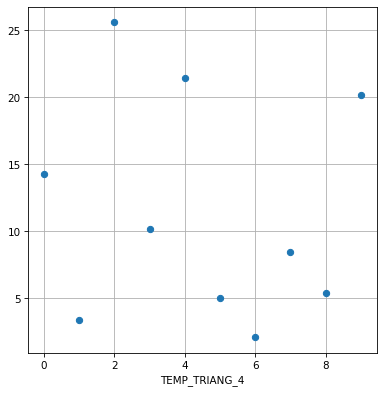

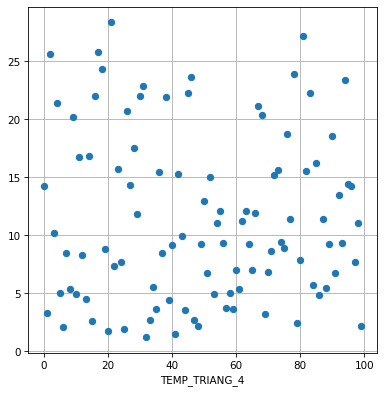

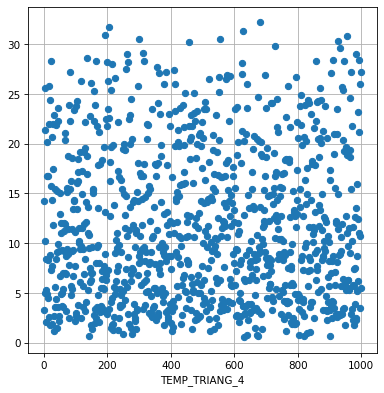

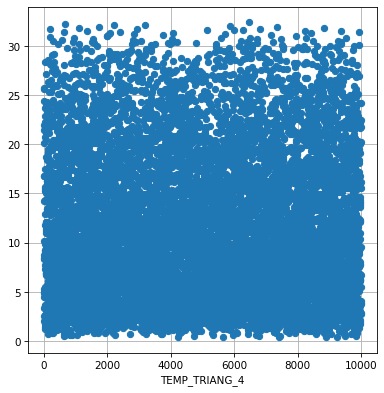

In [86]:
param_triang = res_dftemp4["Parámetros"][4]
a = param_triang[0]  # mínimo
c = param_triang[1]  # moda
b = param_triang[2]  # máximo
loc = a
escalado = b-a
forma = (c-a)/escalado
TEMP_TRIANG_4 = stats.triang(loc = loc, scale = escalado, c = forma)


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n1t = 10

xtemp4_1 = TEMP_TRIANG_4.rvs(size = n1t)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xtemp4_1, 'o')
plt.grid()
plt.xlabel('TEMP_TRIANG_4');
plt.show()



# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n2t = 100

xtemp4_2 = TEMP_TRIANG_4.rvs(size = n2t)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xtemp4_2, 'o')
plt.grid()
plt.xlabel('TEMP_TRIANG_4');
plt.show()


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n3t = 1000

xtemp4_3 = TEMP_TRIANG_4.rvs(size = n3t)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xtemp4_3, 'o')
plt.grid()
plt.xlabel('TEMP_TRIANG_4');
plt.show()


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n4t = 10000

xtemp4_4 = TEMP_TRIANG_4.rvs(size = n4t)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xtemp4_4, 'o')
plt.grid()
plt.xlabel('TEMP_TRIANG_4');
plt.show()

#### IRRADIACIÓN

In [87]:
# .dropna() elimina los valores nulos y .values lo transforma en array
y = df_orig_irrad['IRRAD_CELDA01'].dropna().values
n = len(y)

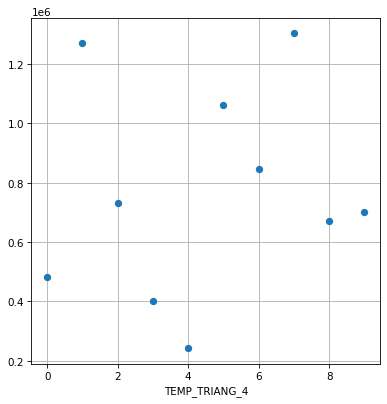

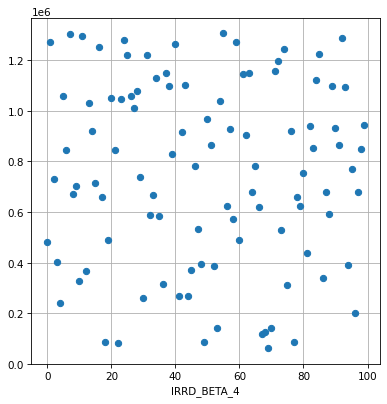

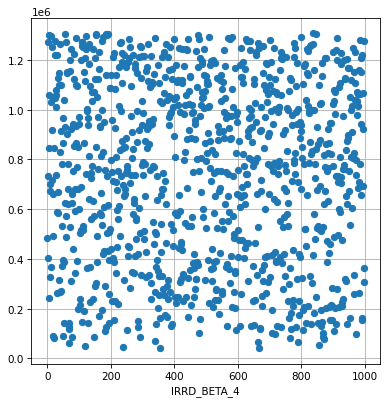

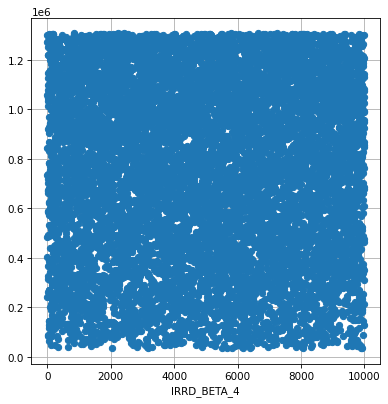

In [88]:
param_beta = res_dfirrd_4["Parámetros"][4]
pi1 = param_beta[0]
pi2 = param_beta[1] 
pi3 = param_beta[2] 
pi4 = param_beta[3]

IRRD_BETA_4 = stats.beta(pi1, pi2, pi3, pi4)



# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n1i = 10

xirrd4_1 = IRRD_BETA_4.rvs(size = n1i)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xirrd4_1, 'o')
plt.grid()
plt.xlabel('TEMP_TRIANG_4');
plt.show()



# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n2i = 100

xirrd4_2 = IRRD_BETA_4.rvs(size = n2i)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xirrd4_2, 'o')
plt.grid()
plt.xlabel('IRRD_BETA_4');
plt.show()


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n3i = 1000

xirrd4_3 = IRRD_BETA_4.rvs(size = n3i)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xirrd4_3, 'o')
plt.grid()
plt.xlabel('IRRD_BETA_4');
plt.show()


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n4i = 10000

xirrd4_4 = IRRD_BETA_4.rvs(size = n4i)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xirrd4_4, 'o')
plt.grid()
plt.xlabel('IRRD_BETA_4');
plt.show()

#### PRECIPITACIÓN

In [89]:
# .dropna() elimina los valores nulos y .values lo transforma en array
z = df_orig_precip['PRECIP_CELDA01'].dropna().values
n = len(z)

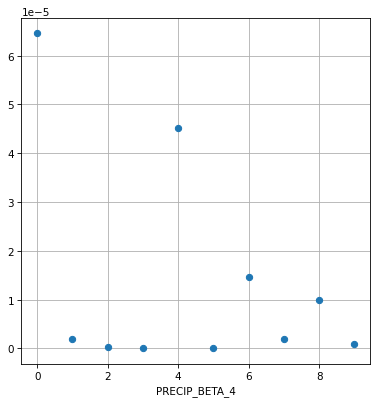

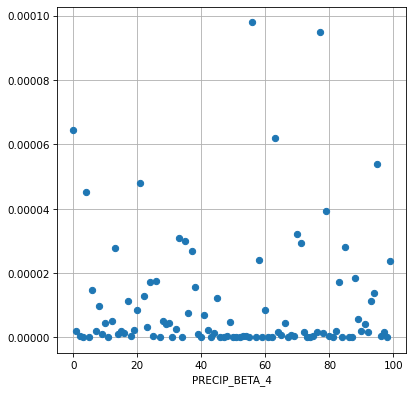

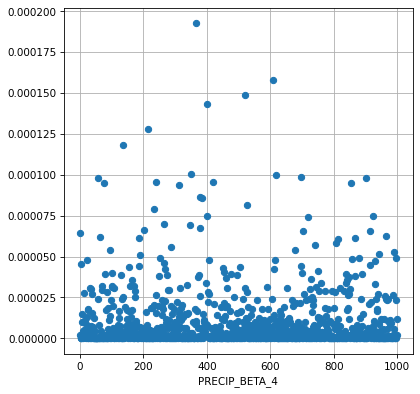

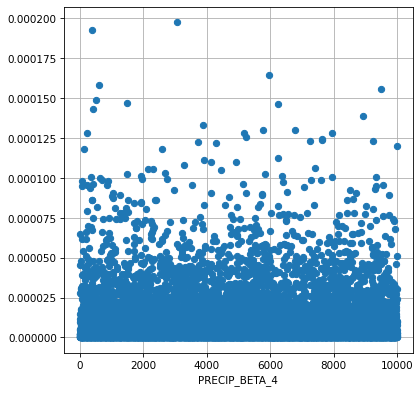

In [92]:
param_beta = res_dfprecip4["Parámetros"][4]
pp1 = param_beta[0]
pp2 = param_beta[1] 
pp3 = param_beta[2] 
pp4 = param_beta[3]

PRECIP_BETA_4 = stats.beta(pp1, pp2, pp3, pp4)



# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n1p = 10

xprecip4_1 = PRECIP_BETA_4.rvs(size = n1p)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xprecip4_1, 'o')
plt.grid()
plt.xlabel('PRECIP_BETA_4');
plt.show()



# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n2p = 100

xprecip4_2 = PRECIP_BETA_4.rvs(size = n2p)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xprecip4_2, 'o')
plt.grid()
plt.xlabel('PRECIP_BETA_4');
plt.show()


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n3p = 1000

xprecip4_3 = PRECIP_BETA_4.rvs(size = n3p)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xprecip4_3, 'o')
plt.grid()
plt.xlabel('PRECIP_BETA_4');
plt.show()


# fijamos la semilla
semilla = 1000
np.random.seed(semilla)
n4p = 10000

xprecip4_4 = PRECIP_BETA_4.rvs(size = n4p)

fig = plt.figure(1, figsize=(6, 6))
plt.plot(xprecip4_4, 'o')
plt.grid()
plt.xlabel('PRECIP_BETA_4');
plt.show()